# Objective Contribution Decomposition (Online vs Replay)

This notebook reads existing experiment outputs only (no simulator calls).
Goal: clearly decompose each objective contribution:
- `raw_objective`
- constraint violations (S21 passband / S11 passband / S21 stopband low / high)
- `penalty_weight * total_violation`
- final `objective = raw_objective + penalty`


In [19]:
from __future__ import annotations

from pathlib import Path
import json
import os
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

NOTEBOOK_DIR = Path.cwd()
REPO_ROOT = NOTEBOOK_DIR if (NOTEBOOK_DIR / 'experiments').exists() else NOTEBOOK_DIR.parent
os.chdir(REPO_ROOT)
if str(REPO_ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / 'src'))

ONLINE_DIR = REPO_ROOT / 'experiments' / 'bo_online'
REPLAY_DIR = REPO_ROOT / 'experiments' / 'bo_replay'

ONLINE_CSVS = [
    ONLINE_DIR / 'bo_online_seed0.csv',
    ONLINE_DIR / 'bo_online_seed1.csv',
    ONLINE_DIR / 'bo_online_seed2.csv',
]

# Switch replay group here, e.g., grid_ucb_beta2_n2_seed*.json
REPLAY_GLOB = 'bo_replay_experiment*.json'

# Objective config (same as bo_online_campaign)
PASSBAND_S21_MIN_DB = -5.0
PASSBAND_S11_MAX_DB = -10.0
STOPBAND_S21_MAX_DB = -25.0
PENALTY_WEIGHT = 100.0

print('repo root:', REPO_ROOT)
print('online files:')
for p in ONLINE_CSVS:
    print(' -', p, 'exists=', p.exists())

replay_files = sorted(REPLAY_DIR.glob(REPLAY_GLOB))
if not replay_files:
    # fallback to legacy replay naming
    replay_files = sorted(REPLAY_DIR.glob('grid_*.json'))

print('replay files matched:', len(replay_files))
for p in replay_files[:5]:
    print(' -', p)


repo root: /home/zhanghf/projects/vector
online files:
 - /home/zhanghf/projects/vector/experiments/bo_online/bo_online_seed0.csv exists= True
 - /home/zhanghf/projects/vector/experiments/bo_online/bo_online_seed1.csv exists= True
 - /home/zhanghf/projects/vector/experiments/bo_online/bo_online_seed2.csv exists= True
replay files matched: 6
 - /home/zhanghf/projects/vector/experiments/bo_replay/bo_replay_experiment_latest_nb.json
 - /home/zhanghf/projects/vector/experiments/bo_replay/bo_replay_experiment_seed0.json
 - /home/zhanghf/projects/vector/experiments/bo_replay/bo_replay_experiment_seed1.json
 - /home/zhanghf/projects/vector/experiments/bo_replay/bo_replay_experiment_seed2.json
 - /home/zhanghf/projects/vector/experiments/bo_replay/bo_replay_experiment_seed3.json


In [20]:
def _safe_float(v, default=np.nan):
    try:
        return float(v)
    except Exception:
        return default


def _extract_online_runs(paths: list[Path]) -> pd.DataFrame:
    runs = []
    for p in paths:
        if not p.exists():
            continue
        df = pd.read_csv(p).copy()
        df['run_id'] = p.stem
        df['group'] = 'online'
        runs.append(df)
    return pd.concat(runs, ignore_index=True) if runs else pd.DataFrame()


def _extract_replay_runs(json_paths: list[Path]) -> pd.DataFrame:
    rows = []
    for p in json_paths:
        payload = json.loads(p.read_text())
        for t in payload.get('trials', []):
            m = t.get('metrics', {}) or {}
            rows.append({
                'iteration': t.get('iteration'),
                'objective': _safe_float(t.get('objective')),
                'best_so_far': _safe_float(t.get('best_so_far')),
                'metric_s21_mean_5200000000_5900000000': _safe_float(m.get('s21_mean_5200000000_5900000000', m.get('passband_s21_mean_db'))),
                'metric_s11_max_5200000000_5900000000': _safe_float(m.get('s11_max_5200000000_5900000000', m.get('passband_s11_max_db'))),
                'metric_s21_max_3600000000_4800000000': _safe_float(m.get('s21_max_3600000000_4800000000', m.get('lower_stopband_s21_max_db'))),
                'metric_s21_max_6500000000_8700000000': _safe_float(m.get('s21_max_6500000000_8700000000', m.get('upper_stopband_s21_max_db'))),
                'metric_raw_objective': _safe_float(m.get('raw_objective')),
                'metric_total_positive_violation': _safe_float(m.get('total_positive_violation')),
                'metric_penalty': _safe_float(m.get('penalty')),
                'run_id': p.stem,
                'group': 'replay',
            })
    return pd.DataFrame(rows)


online_df = _extract_online_runs(ONLINE_CSVS)
replay_df = _extract_replay_runs(replay_files)

print('online rows=', len(online_df), 'replay rows=', len(replay_df))
display(online_df.head(3))
display(replay_df.head(3))


online rows= 68 replay rows= 240


,iteration,step,phase,dataset_index,geometry,case_id,objective,predicted_mean,predicted_uncertainty,acquisition_score,...,metric_s21_mean_5200000000_5900000000,metric_s21_peak_freq_5200000000_5900000000,metric_s11_max_5200000000_5900000000,metric_s21_max_3600000000_4800000000,metric_s21_max_6500000000_8700000000,metric_raw_objective,metric_total_positive_violation,metric_penalty,run_id,group
0,0,NaN,init,NaN,"[7.827392337464291, 8.053957342752774, 7.80819...",bo_online_seed0_it0000,3342.180283,NaN,NaN,NaN,...,-6.073518,5.411000e+09,-0.208788,-2.507634,-33.720334,6.470661,33.357096,3335.709622,bo_online_seed0,online
1,1,NaN,init,NaN,"[7.808724998293084, 8.187014484757553, 7.96317...",bo_online_seed0_it0001,3329.487426,NaN,NaN,NaN,...,-4.737724,5.203000e+09,-0.239817,-1.522600,-32.733971,5.729152,33.237583,3323.758273,bo_online_seed0,online
2,2,NaN,bo,NaN,"[7.872635784469978, 8.108292244049817, 7.85994...",bo_online_seed0_it0002,3156.228422,3335.833854,1.0,-3331.833854,...,-4.934287,5.450000e+09,-0.337795,-3.152121,-31.495128,5.220001,31.510084,3151.008421,bo_online_seed0,online


,iteration,objective,best_so_far,metric_s21_mean_5200000000_5900000000,metric_s11_max_5200000000_5900000000,metric_s21_max_3600000000_4800000000,metric_s21_max_6500000000_8700000000,metric_raw_objective,metric_total_positive_violation,metric_penalty,run_id,group
0,0,978.398959,978.398959,-0.936473,-4.631172,-21.684827,-23.915061,1.505044,9.768939,976.893915,bo_replay_experiment_latest_nb,replay
1,1,752.502809,752.502809,-1.403861,-2.489125,-28.981112,-28.908862,1.415289,7.510875,751.087520,bo_replay_experiment_latest_nb,replay
2,2,747.581466,747.581466,-1.434201,-2.543470,-27.820389,-27.919523,1.928487,7.456530,745.652980,bo_replay_experiment_latest_nb,replay


In [21]:
def add_contribution_columns(df: pd.DataFrame) -> pd.DataFrame:
    if df.empty:
        return df
    out = df.copy()

    # Constraint violations (same definitions as in the objective constraints)
    out['viol_s21_passband'] = (PASSBAND_S21_MIN_DB - out['metric_s21_mean_5200000000_5900000000']).clip(lower=0)
    out['viol_s11_passband'] = (out['metric_s11_max_5200000000_5900000000'] - PASSBAND_S11_MAX_DB).clip(lower=0)
    out['viol_s21_stop_low'] = (out['metric_s21_max_3600000000_4800000000'] - STOPBAND_S21_MAX_DB).clip(lower=0)
    out['viol_s21_stop_high'] = (out['metric_s21_max_6500000000_8700000000'] - STOPBAND_S21_MAX_DB).clip(lower=0)

    out['viol_total_recomputed'] = out[['viol_s21_passband','viol_s11_passband','viol_s21_stop_low','viol_s21_stop_high']].sum(axis=1)
    out['penalty_recomputed'] = PENALTY_WEIGHT * out['viol_total_recomputed']

    # Fill missing logged terms from recomputed values
    out['metric_total_positive_violation'] = out['metric_total_positive_violation'].where(out['metric_total_positive_violation'].notna(), out['viol_total_recomputed'])
    out['metric_penalty'] = out['metric_penalty'].where(out['metric_penalty'].notna(), out['penalty_recomputed'])

    # If raw missing, infer from objective - penalty
    out['metric_raw_objective'] = out['metric_raw_objective'].where(out['metric_raw_objective'].notna(), out['objective'] - out['metric_penalty'])

    out['objective_reconstructed'] = out['metric_raw_objective'] + out['metric_penalty']
    out['objective_residual'] = out['objective'] - out['objective_reconstructed']

    return out

online_df = add_contribution_columns(online_df)
replay_df = add_contribution_columns(replay_df)

check = pd.concat([
    online_df.assign(group='online')[['group','objective','objective_reconstructed','objective_residual']].head(5),
    replay_df.assign(group='replay')[['group','objective','objective_reconstructed','objective_residual']].head(5),
], ignore_index=True)
display(check)


,group,objective,objective_reconstructed,objective_residual
0,online,3342.180283,3342.180283,0.000000e+00
1,online,3329.487426,3329.487426,0.000000e+00
2,online,3156.228422,3156.228422,0.000000e+00
3,online,3280.290094,3280.290094,0.000000e+00
4,online,2906.376785,2906.376785,-4.547474e-13
5,replay,978.398959,978.398959,0.000000e+00
6,replay,752.502809,752.502809,0.000000e+00
7,replay,747.581466,747.581466,0.000000e+00
8,replay,791.916210,791.916210,0.000000e+00
9,replay,752.158009,752.158009,0.000000e+00


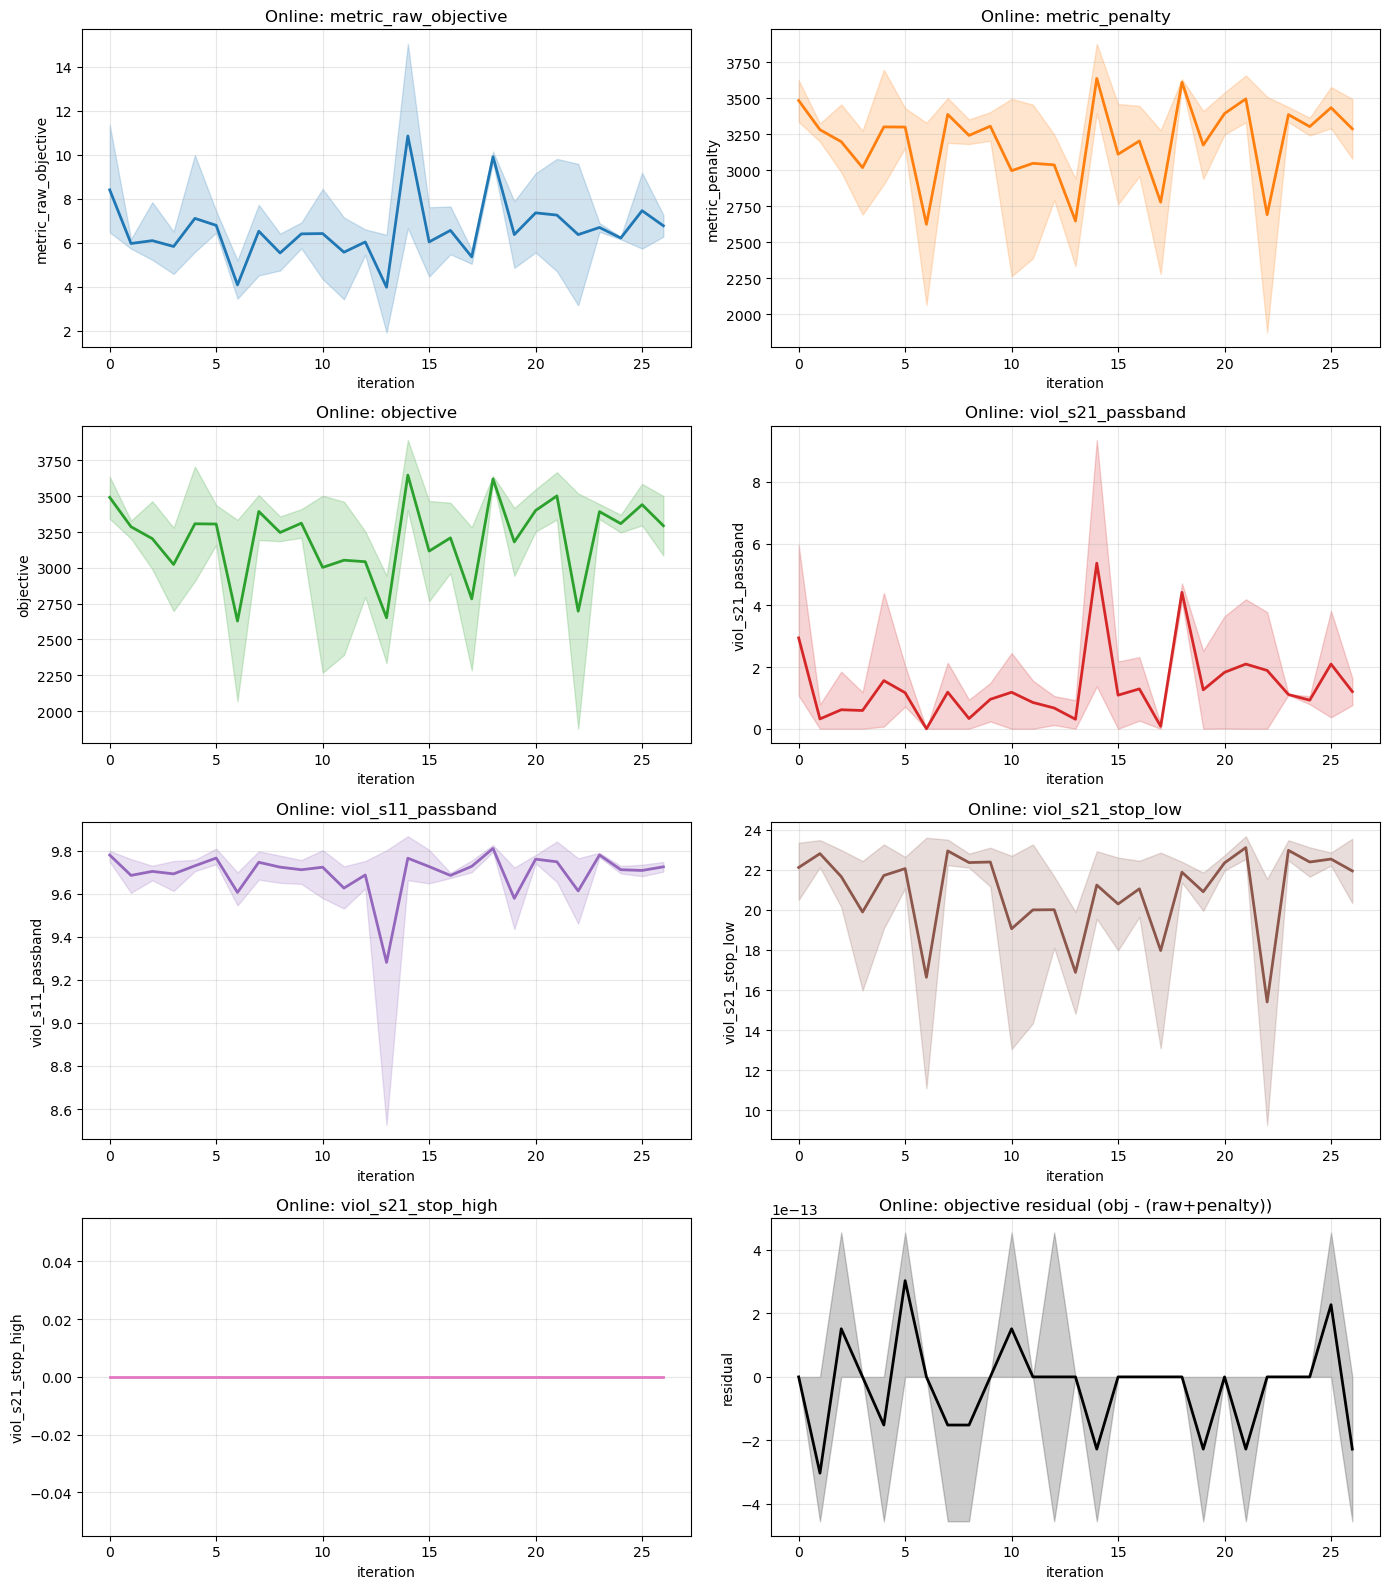

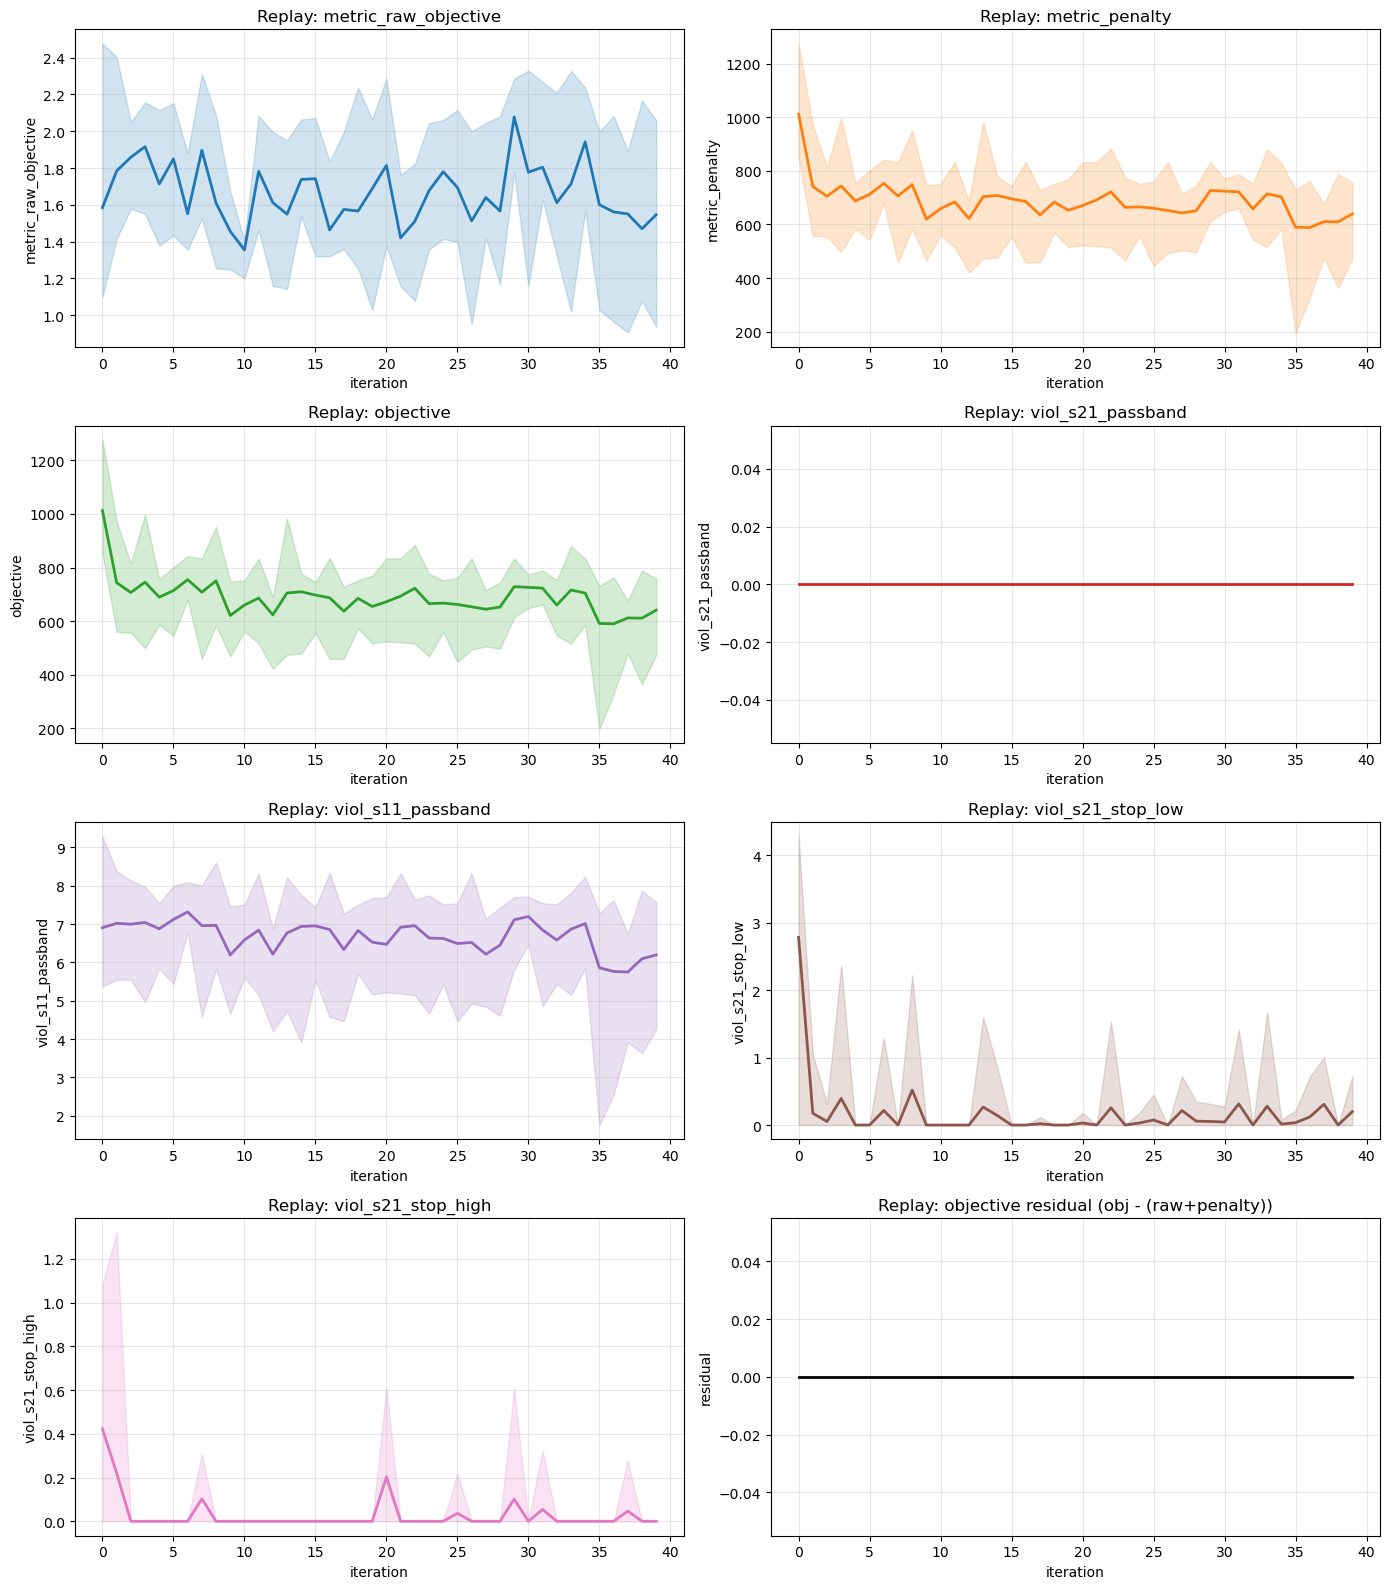

In [22]:
def mean_band_by_iteration(df: pd.DataFrame, col: str) -> pd.DataFrame:
    if df.empty or col not in df.columns:
        return pd.DataFrame()
    g = df.dropna(subset=[col]).groupby('iteration', as_index=False)[col].agg(mean='mean', min='min', max='max')
    return g.sort_values('iteration').reset_index(drop=True)


def plot_mean_band(ax, summary: pd.DataFrame, title: str, ylabel: str, color: str):
    if summary.empty:
        ax.set_title(title + ' (no data)')
        return
    x = summary['iteration'].to_numpy()
    y = summary['mean'].to_numpy()
    ax.plot(x, y, color=color, lw=2)
    ax.fill_between(x, summary['min'].to_numpy(), summary['max'].to_numpy(), color=color, alpha=0.2)
    ax.set_title(title)
    ax.set_xlabel('iteration')
    ax.set_ylabel(ylabel)
    ax.grid(True, alpha=0.3)


def plot_contribution_panels(df: pd.DataFrame, group_name: str):
    contrib_cols = [
        'metric_raw_objective',
        'metric_penalty',
        'objective',
        'viol_s21_passband',
        'viol_s11_passband',
        'viol_s21_stop_low',
        'viol_s21_stop_high',
    ]

    fig, axes = plt.subplots(4, 2, figsize=(14, 16))
    axes = axes.ravel()
    colors = ['tab:blue','tab:orange','tab:green','tab:red','tab:purple','tab:brown','tab:pink']

    for i,(col,color) in enumerate(zip(contrib_cols,colors)):
        s = mean_band_by_iteration(df, col)
        plot_mean_band(axes[i], s, f'{group_name}: {col}', col, color)

    # residual check
    s = mean_band_by_iteration(df, 'objective_residual')
    plot_mean_band(axes[-1], s, f'{group_name}: objective residual (obj - (raw+penalty))', 'residual', 'black')

    plt.tight_layout()
    plt.show()


plot_contribution_panels(online_df, 'Online')
plot_contribution_panels(replay_df, 'Replay')


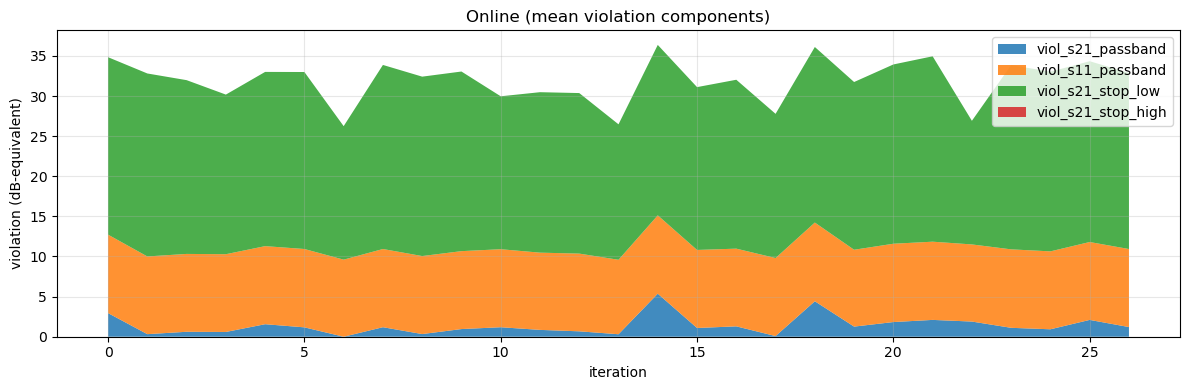

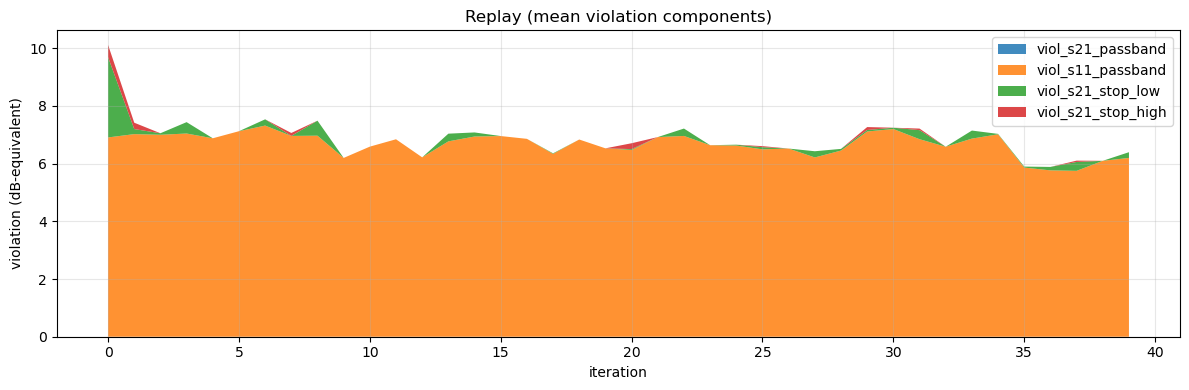

In [23]:
def stacked_penalty_contrib(df: pd.DataFrame, title: str):
    if df.empty:
        print(title, 'no data')
        return
    g = df.groupby('iteration', as_index=False)[['viol_s21_passband','viol_s11_passband','viol_s21_stop_low','viol_s21_stop_high']].mean()
    x = g['iteration'].to_numpy()

    v1 = g['viol_s21_passband'].to_numpy()
    v2 = g['viol_s11_passband'].to_numpy()
    v3 = g['viol_s21_stop_low'].to_numpy()
    v4 = g['viol_s21_stop_high'].to_numpy()

    fig, ax = plt.subplots(1,1,figsize=(12,4))
    ax.stackplot(x, v1, v2, v3, v4, labels=['viol_s21_passband','viol_s11_passband','viol_s21_stop_low','viol_s21_stop_high'], alpha=0.85)
    ax.set_title(title + ' (mean violation components)')
    ax.set_xlabel('iteration')
    ax.set_ylabel('violation (dB-equivalent)')
    ax.grid(True, alpha=0.3)
    ax.legend(loc='upper right')
    plt.tight_layout()
    plt.show()


stacked_penalty_contrib(online_df, 'Online')
stacked_penalty_contrib(replay_df, 'Replay')


In [24]:
def contribution_stats(df: pd.DataFrame, group: str) -> pd.DataFrame:
    if df.empty:
        return pd.DataFrame()
    cols = [
        'objective', 'metric_raw_objective', 'metric_penalty',
        'viol_s21_passband','viol_s11_passband','viol_s21_stop_low','viol_s21_stop_high',
        'metric_total_positive_violation','objective_residual',
    ]
    rows=[]
    for c in cols:
        if c not in df.columns:
            continue
        s = pd.to_numeric(df[c], errors='coerce').dropna()
        if s.empty:
            continue
        rows.append({
            'group': group, 'metric': c,
            'mean': float(s.mean()), 'median': float(s.median()),
            'p90': float(s.quantile(0.9)), 'max': float(s.max())
        })
    return pd.DataFrame(rows)

stats = pd.concat([contribution_stats(online_df,'online'), contribution_stats(replay_df,'replay')], ignore_index=True)
display(stats.sort_values(['metric','group']).reset_index(drop=True))

# Additionally report mean absolute contribution ratios (penalty/raw vs objective).
ratio_rows=[]
for name,df in [('online',online_df),('replay',replay_df)]:
    if df.empty:
        continue
    d=df[['objective','metric_penalty','metric_raw_objective']].dropna().copy()
    if len(d)==0:
        continue
    d['penalty_share_abs']=np.abs(d['metric_penalty'])/(np.abs(d['objective'])+1e-12)
    d['raw_share_abs']=np.abs(d['metric_raw_objective'])/(np.abs(d['objective'])+1e-12)
    ratio_rows.append({
        'group':name,
        'penalty_share_abs_mean':float(d['penalty_share_abs'].mean()),
        'raw_share_abs_mean':float(d['raw_share_abs'].mean()),
    })
display(pd.DataFrame(ratio_rows))


,group,metric,mean,median,p90,max
0,online,metric_penalty,3.185281e+03,3301.869609,3550.198370,3.877384e+03
1,replay,metric_penalty,6.864717e+02,701.941800,831.190864,1.273625e+03
2,online,metric_raw_objective,6.478171e+00,6.316876,9.303263,1.504946e+01
3,replay,metric_raw_objective,1.664046e+00,1.591844,2.116278,2.475866e+00
4,online,metric_total_positive_violation,3.185281e+01,33.018696,35.501984,3.877384e+01
5,replay,metric_total_positive_violation,6.864717e+00,7.019418,8.311909,1.273625e+01
6,online,objective,3.191759e+03,3307.724942,3559.361841,3.892433e+03
7,replay,objective,6.881357e+02,703.429349,832.965273,1.276101e+03
8,online,objective_residual,-2.674984e-14,0.000000,0.000000,4.547474e-13
9,replay,objective_residual,0.000000e+00,0.000000,0.000000,0.000000e+00


,group,penalty_share_abs_mean,raw_share_abs_mean
0,online,0.998001,0.001999
1,replay,0.997523,0.002477


## Read This First

- If `metric_penalty` is much larger than `metric_raw_objective`, objective scale is dominated by constraint violations.
- `objective_residual` should be close to 0; otherwise, metric definitions in that history may differ from current assumptions.
- You can change `REPLAY_GLOB` to compare different replay groups.


## Nearest Dataset Point to Online Best Objective

This section finds the original dataset sample whose objective is closest to the online best objective, then compares their S21/S11 curves by bands.


In [25]:
import yaml
from optimization.datasets import BCLFDataset
from optimization.objectives import build_bclf_objective

def pick_online_best_trial(online_dir: Path):
    best = None
    best_obj = float('inf')
    best_file = None
    for p in sorted(online_dir.glob('bo_online_seed*.json')):
        payload = json.loads(p.read_text())
        for t in payload.get('trials', []):
            obj = float(t.get('objective', float('inf')))
            if np.isfinite(obj) and obj < best_obj:
                best_obj = obj
                best = t
                best_file = p
    if best is None:
        raise RuntimeError('No online trial found')
    return best_file, best, best_obj


def build_freqs_from_config(config_path: Path) -> np.ndarray:
    cfg = yaml.safe_load(config_path.read_text())
    fc = cfg['data']['freqs']
    return np.arange(fc['min'], fc['max'], fc['step'], dtype=float)


online_best_file, online_best_trial, online_best_obj = pick_online_best_trial(ONLINE_DIR)
print('online best file =', online_best_file.name)
print('online best objective =', online_best_obj)
print('online best case_id =', online_best_trial.get('case_id'))

freqs_ds = build_freqs_from_config(REPO_ROOT / 'configs' / 'filter_bnn_online_uaw_uaw.yaml')
dataset = BCLFDataset.from_pickle(REPO_ROOT / 'data' / 'filter_bnn_online_uaw_uaw_dataset.pkl', freqs=freqs_ds)

objective = build_bclf_objective(
    passband_hz=(5.2e9, 5.9e9),
    lower_stopband_hz=(3.6e9, 4.8e9),
    upper_stopband_hz=(6.5e9, 8.7e9),
    target_center_hz=5.55e9,
    min_passband_s21_db=-5.0,
    max_passband_s11_db=-10.0,
    max_stopband_s21_db=-25.0,
    center_weight=2.0,
    penalty_weight=100.0,
)

# Evaluate objective on original dataset and pick sample closest to online-best objective
closest_idx = None
closest_obj = None
closest_abs_diff = float('inf')

for i in range(len(dataset)):
    s = np.asarray(dataset.S_pool[i], dtype=complex)
    r = objective.evaluate(freqs_ds, s)
    obj_i = float(r.objective)
    d = abs(obj_i - online_best_obj)
    if d < closest_abs_diff:
        closest_abs_diff = d
        closest_idx = i
        closest_obj = obj_i

print('closest dataset index =', closest_idx)
print('closest dataset objective =', closest_obj)
print('abs diff to online best =', closest_abs_diff)

online_geom = online_best_trial.get('geometry', {})
if isinstance(online_geom, dict):
    print('online best geometry =', online_geom)

replay_geom = dict(zip(['L','L1','L2','W','W1','W2','S1','S2'], np.asarray(dataset.X_pool[closest_idx], dtype=float).tolist()))
print('closest dataset geometry =', replay_geom)


online best file = bo_online_seed1.json
online best objective = 1876.2249295114664
online best case_id = bo_online_seed1_it0022
closest dataset index = 1036
closest dataset objective = 1633.1160035216803
abs diff to online best = 243.10892598978603
closest dataset geometry = {'L': 7.7, 'L1': 8.2, 'L2': 8.0, 'W': 1.1, 'W1': 0.7, 'W2': 1.1, 'S1': 0.13, 'S2': 0.55}


In [26]:
def parse_touchstone_s2p_ma(path: Path) -> tuple[np.ndarray, np.ndarray]:
    unit_scale = {'hz':1.0, 'khz':1e3, 'mhz':1e6, 'ghz':1e9}
    freq_mul = None
    rows = []
    with path.open('r', encoding='utf-8', errors='ignore') as f:
        for raw in f:
            line = raw.strip()
            if not line or line.startswith('!'):
                continue
            if line.startswith('#'):
                parts = line[1:].strip().lower().split()
                if len(parts) >= 3:
                    freq_mul = unit_scale[parts[0]]
                    if parts[1] != 's' or parts[2] != 'ma':
                        raise ValueError('Only S MA touchstone supported')
                continue
            vals = line.split()
            if len(vals) >= 9:
                rows.append([float(v) for v in vals[:9]])
    arr = np.asarray(rows, dtype=float)
    if arr.size == 0 or freq_mul is None:
        raise RuntimeError(f'Failed parsing touchstone: {path}')

    def ma_to_c(mag, ang_deg):
        return mag * np.exp(1j * np.deg2rad(ang_deg))

    f = arr[:,0] * freq_mul
    s = np.zeros((2,2,len(f)), dtype=complex)
    s[0,0,:] = ma_to_c(arr[:,1], arr[:,2])
    s[1,0,:] = ma_to_c(arr[:,3], arr[:,4])
    s[0,1,:] = ma_to_c(arr[:,5], arr[:,6])
    s[1,1,:] = ma_to_c(arr[:,7], arr[:,8])
    return f, s


def db20(x):
    return 20*np.log10(np.maximum(np.abs(x), 1e-15))

# Load online-best response from Touchstone
sm = online_best_trial.get('simulation_metadata', {}) or {}
touchstone_rel = sm.get('touchstone_path')
if touchstone_rel is None:
    rj_rel = sm.get('result_json_path')
    if rj_rel is None:
        raise RuntimeError('Online best trial has no touchstone reference')
    rj = REPO_ROOT / rj_rel
    rd = json.loads(rj.read_text())
    touchstone_rel = rd.get('artifacts', {}).get('touchstone')

touchstone_path = REPO_ROOT / touchstone_rel
f_online, s_online = parse_touchstone_s2p_ma(touchstone_path)

# Load closest original dataset response
f_ds = np.asarray(dataset.freqs, dtype=float)
s_ds = np.asarray(dataset.S_pool[closest_idx], dtype=complex)

print('online touchstone =', touchstone_path)
print('online shape =', s_online.shape, '| dataset shape =', s_ds.shape)


online touchstone = /home/zhanghf/projects/vector/data/bandpass_coupled_line_filter_export/ext/Bandpass_Coupled_Line_Filter_export_Bandpass_Coupled_Line_Filter_L_7d78_L1_8d14_L2_7d87_W_1d02_W1_0d85_W2_0d93_S1_0d14_S2_0d6.s2p
online shape = (2, 2, 401) | dataset shape = (2, 2, 401)


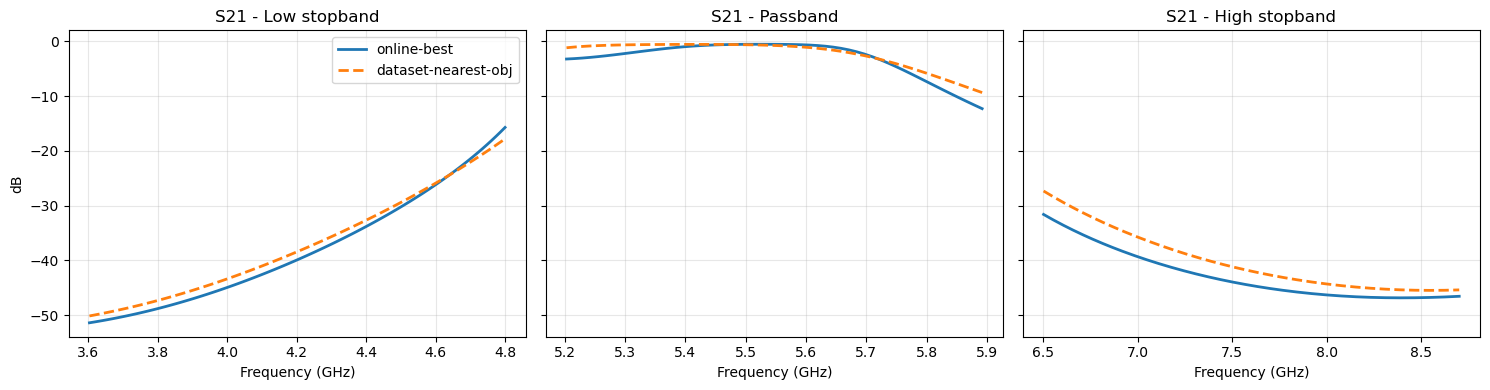

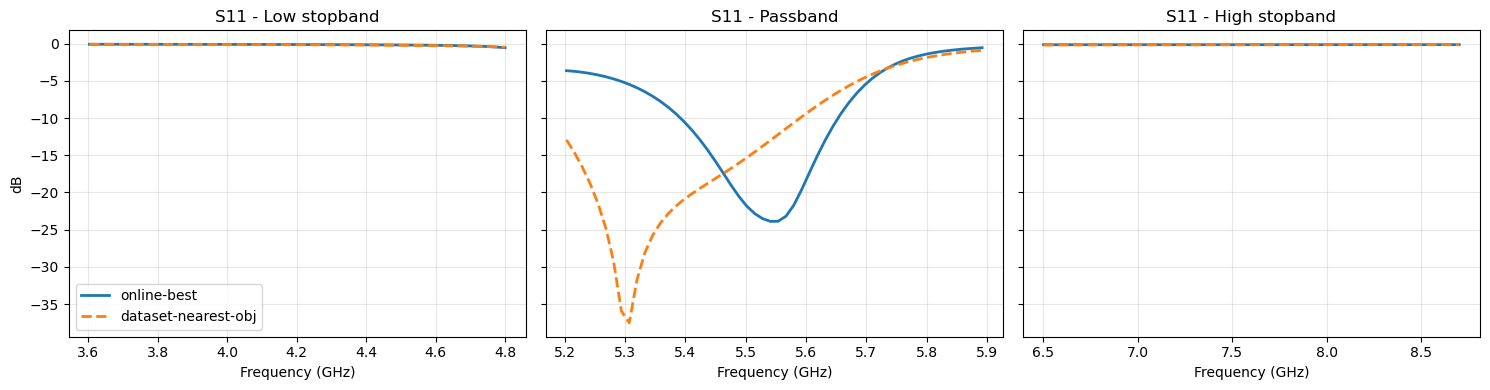

In [27]:
LOW_STOPBAND = (3.6e9, 4.8e9)
PASSBAND = (5.2e9, 5.9e9)
HIGH_STOPBAND = (6.5e9, 8.7e9)

def band_mask(freq_hz: np.ndarray, band: tuple[float, float]) -> np.ndarray:
    return (freq_hz >= band[0]) & (freq_hz <= band[1])


def plot_by_bands(freq_online, s_online, freq_ds, s_ds):
    bands = [
        ('Low stopband', LOW_STOPBAND),
        ('Passband', PASSBAND),
        ('High stopband', HIGH_STOPBAND),
    ]

    # Figure 1: S21 by bands
    fig1, axes1 = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
    for i, (name, b) in enumerate(bands):
        mo = band_mask(freq_online, b)
        md = band_mask(freq_ds, b)
        axes1[i].plot(freq_online[mo]/1e9, db20(s_online[1,0,mo]), lw=2, label='online-best')
        axes1[i].plot(freq_ds[md]/1e9, db20(s_ds[1,0,md]), lw=2, ls='--', label='dataset-nearest-obj')
        axes1[i].set_title(f'S21 - {name}')
        axes1[i].set_xlabel('Frequency (GHz)')
        axes1[i].grid(True, alpha=0.3)
    axes1[0].set_ylabel('dB')
    axes1[0].legend(loc='best')
    plt.tight_layout()
    plt.show()

    # Figure 2: S11 by bands
    fig2, axes2 = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
    for i, (name, b) in enumerate(bands):
        mo = band_mask(freq_online, b)
        md = band_mask(freq_ds, b)
        axes2[i].plot(freq_online[mo]/1e9, db20(s_online[0,0,mo]), lw=2, label='online-best')
        axes2[i].plot(freq_ds[md]/1e9, db20(s_ds[0,0,md]), lw=2, ls='--', label='dataset-nearest-obj')
        axes2[i].set_title(f'S11 - {name}')
        axes2[i].set_xlabel('Frequency (GHz)')
        axes2[i].grid(True, alpha=0.3)
    axes2[0].set_ylabel('dB')
    axes2[0].legend(loc='best')
    plt.tight_layout()
    plt.show()


plot_by_bands(f_online, s_online, f_ds, s_ds)


### Full-band Overview (Online best vs Dataset-nearest objective)


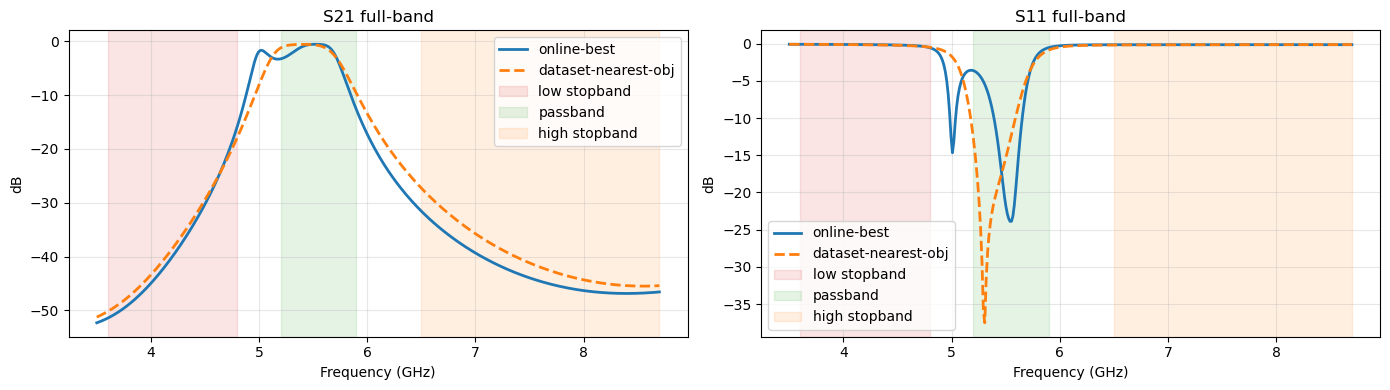

In [28]:
def plot_full_overview(freq_online, s_online, freq_ds, s_ds):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4), sharex=False)

    # S21 full-band
    axes[0].plot(freq_online/1e9, db20(s_online[1,0,:]), lw=2, label='online-best')
    axes[0].plot(freq_ds/1e9, db20(s_ds[1,0,:]), lw=2, ls='--', label='dataset-nearest-obj')
    axes[0].axvspan(LOW_STOPBAND[0]/1e9, LOW_STOPBAND[1]/1e9, alpha=0.12, color='tab:red', label='low stopband')
    axes[0].axvspan(PASSBAND[0]/1e9, PASSBAND[1]/1e9, alpha=0.12, color='tab:green', label='passband')
    axes[0].axvspan(HIGH_STOPBAND[0]/1e9, HIGH_STOPBAND[1]/1e9, alpha=0.12, color='tab:orange', label='high stopband')
    axes[0].set_title('S21 full-band')
    axes[0].set_xlabel('Frequency (GHz)')
    axes[0].set_ylabel('dB')
    axes[0].grid(True, alpha=0.3)

    # S11 full-band
    axes[1].plot(freq_online/1e9, db20(s_online[0,0,:]), lw=2, label='online-best')
    axes[1].plot(freq_ds/1e9, db20(s_ds[0,0,:]), lw=2, ls='--', label='dataset-nearest-obj')
    axes[1].axvspan(LOW_STOPBAND[0]/1e9, LOW_STOPBAND[1]/1e9, alpha=0.12, color='tab:red', label='low stopband')
    axes[1].axvspan(PASSBAND[0]/1e9, PASSBAND[1]/1e9, alpha=0.12, color='tab:green', label='passband')
    axes[1].axvspan(HIGH_STOPBAND[0]/1e9, HIGH_STOPBAND[1]/1e9, alpha=0.12, color='tab:orange', label='high stopband')
    axes[1].set_title('S11 full-band')
    axes[1].set_xlabel('Frequency (GHz)')
    axes[1].set_ylabel('dB')
    axes[1].grid(True, alpha=0.3)

    for ax in axes:
        handles, labels = ax.get_legend_handles_labels()
        uniq = dict(zip(labels, handles))
        ax.legend(uniq.values(), uniq.keys(), loc='best')

    plt.tight_layout()
    plt.show()

plot_full_overview(f_online, s_online, f_ds, s_ds)
